In [26]:
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import pandas as pd
import pystormtracker as pst
from pathlib import Path
import cartopy.crs as ccrs

import sys
import os

module_dir = (Path.cwd() / ".."/".." / "algorithms"/ "track_style_alg").resolve()
sys.path.insert(0,str(module_dir))
import validation as val
import processing as pro
import helpers
from configs import *

import importlib
importlib.reload(val)  # pick up edits in validation.py without restarting the kernel
importlib.reload(pro)  # pick up edits in processing.py without restarting the kernel



<module 'processing' from '/Users/asgerthormann/Documents/uni/master/master_code/master_thesis/algorithms/track_style_alg/processing.py'>

In [27]:
TIME_RANGE = ('1998-12-01 00:00:00', '1999-02-28 18:00:00')  # time range for the validation tracks
df_validation = val.load_tracks('/Users/asgerthormann/Documents/uni/master/master_code/master_thesis/validation_tracks_data/ERA5_19981999_TRACKS_FILTERED_pos.addmslp', start_time=TIME_RANGE[0], end_time=TIME_RANGE[1])
df_validation=df_validation.rename(columns={'vorticity': 'vo'})

In [28]:
df_validation

,step,lon,lat,vo,mslp_lon,mslp_lat,mslp,track_id,time
obs,,,,,,,,,
0,1,0.487187,45.558174,2.945488,NaN,NaN,1024.025,3,1998-12-01 00:00:00
1,2,-2.346924,44.636440,2.743430,359.6110,42.38197,1017.109,3,1998-12-01 06:00:00
2,3,-7.956207,39.646866,3.258656,NaN,NaN,1017.025,3,1998-12-01 12:00:00
3,4,-9.561157,37.609779,3.978987,NaN,NaN,1012.945,3,1998-12-01 18:00:00
4,5,-9.764160,36.040455,4.625281,352.7589,35.01079,1010.072,3,1998-12-02 00:00:00
...,...,...,...,...,...,...,...,...,...
8523,351,174.133652,85.109848,3.723335,NaN,NaN,1024.317,2562,1999-02-26 12:00:00
8524,352,161.192886,84.471527,3.298671,NaN,NaN,1028.030,2562,1999-02-26 18:00:00
8525,353,150.237457,83.856377,2.820443,NaN,NaN,1031.977,2562,1999-02-27 00:00:00


In [29]:
df_validation = val.clip_to_domain(df_validation, DOMAIN, TIME_RANGE)

In [30]:
tracks_validation = val.dataframe_to_tracks(df_validation, variable = 'vo', scale=1e-5)  # convert to s^-1

/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


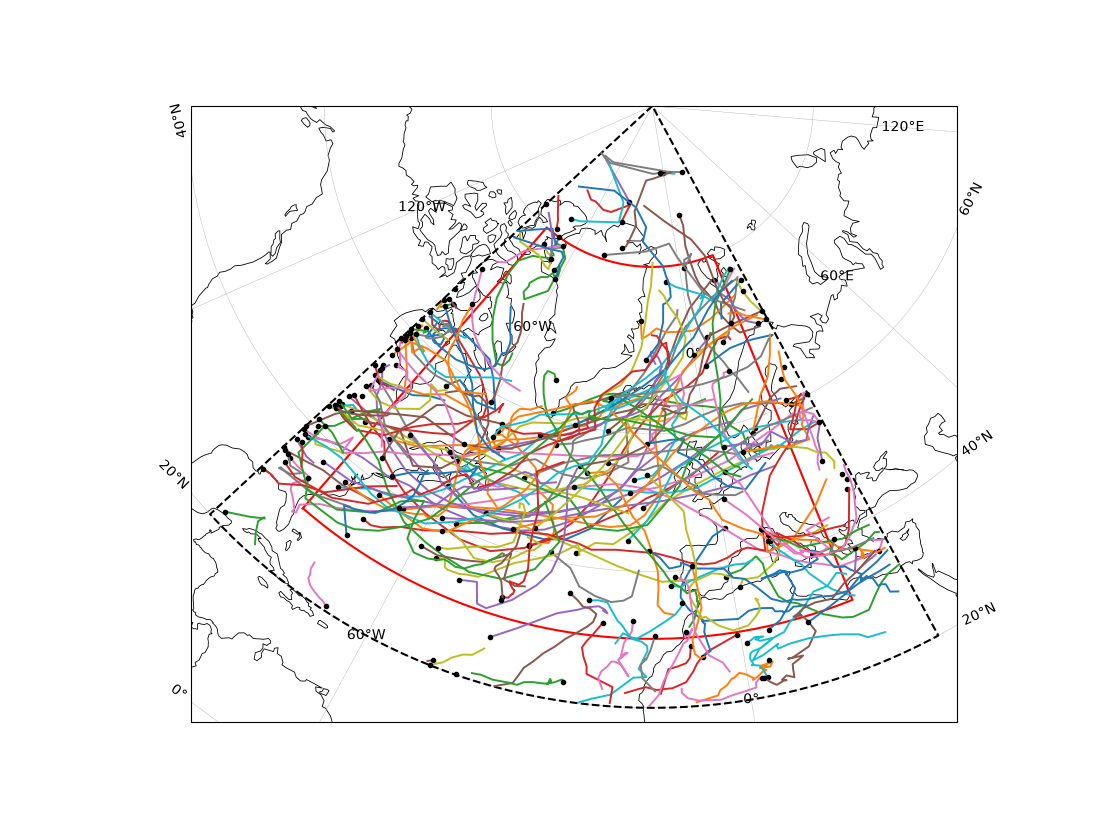

In [31]:
ax = val.plot_regional_tracks(tracks_validation, region=REGION, domain=DOMAIN) 

In [32]:
tracks_validation, summary_validation, points_validation = pro.postprocess_tracks(tracks_validation, **POSTPROCESS_CONFIG)

In [33]:
report = pro.filter_report(summary_validation)

raw tracks: 208, kept: 120


# Full globe tracks

In [34]:
tracks = pst.load_tracks('/Users/asgerthormann/Documents/uni/master/master_code/master_thesis/trackjson/19981999_DJF_vo_spectral_taper.trackjson')
tracks.metadata.processing

(ProcessingStep(operation='spectral_filter', enabled=True, parameters=mappingproxy({'method': 'sht', 'lmin': 5, 'lmax': 42, 'spectral_taper': 0.1})),)

In [35]:
df = helpers.tracks_to_points(tracks)
df

,track_id,time,lat,lon,object_gridcell_area_km2,object_moment_fitted_area_km2,object_moment_major_axis_km,object_moment_minor_axis_km,object_moment_orientation_degrees,raw_value,vo
0,1,1998-12-15 00:00:00,-26.50,-21.25,0.0,0.0,0.0,0.0,0.0,0.000019,0.000019
1,1,1998-12-15 06:00:00,-27.00,-22.00,0.0,0.0,0.0,0.0,0.0,0.000021,0.000021
2,1,1998-12-15 12:00:00,-26.75,-25.00,0.0,0.0,0.0,0.0,0.0,0.000021,0.000021
3,1,1998-12-15 18:00:00,-27.50,-24.50,0.0,0.0,0.0,0.0,0.0,0.000019,0.000019
4,1,1998-12-16 00:00:00,-28.50,-22.25,0.0,0.0,0.0,0.0,0.0,0.000018,0.000018
...,...,...,...,...,...,...,...,...,...,...,...
36138,6253,1999-02-26 06:00:00,-80.00,-97.25,0.0,0.0,0.0,0.0,0.0,0.000031,0.000031
36139,6253,1999-02-26 12:00:00,-79.75,-98.25,0.0,0.0,0.0,0.0,0.0,0.000029,0.000029
36140,6253,1999-02-26 18:00:00,-79.75,-97.50,0.0,0.0,0.0,0.0,0.0,0.000028,0.000028
36141,6253,1999-02-27 00:00:00,-79.75,-95.00,0.0,0.0,0.0,0.0,0.0,0.000025,0.000025


In [36]:
df = val.clip_to_domain(df, DOMAIN, TIME_RANGE)
len(df['track_id'].unique())

506

In [37]:
tracks = val.dataframe_to_tracks(df, variable = 'vo', scale=1)  # already in s^-1


In [38]:
tracks, summary, points = pro.postprocess_tracks(tracks, **POSTPROCESS_CONFIG)

In [39]:
report = pro.filter_report(summary)


raw tracks: 506, kept: 129


/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


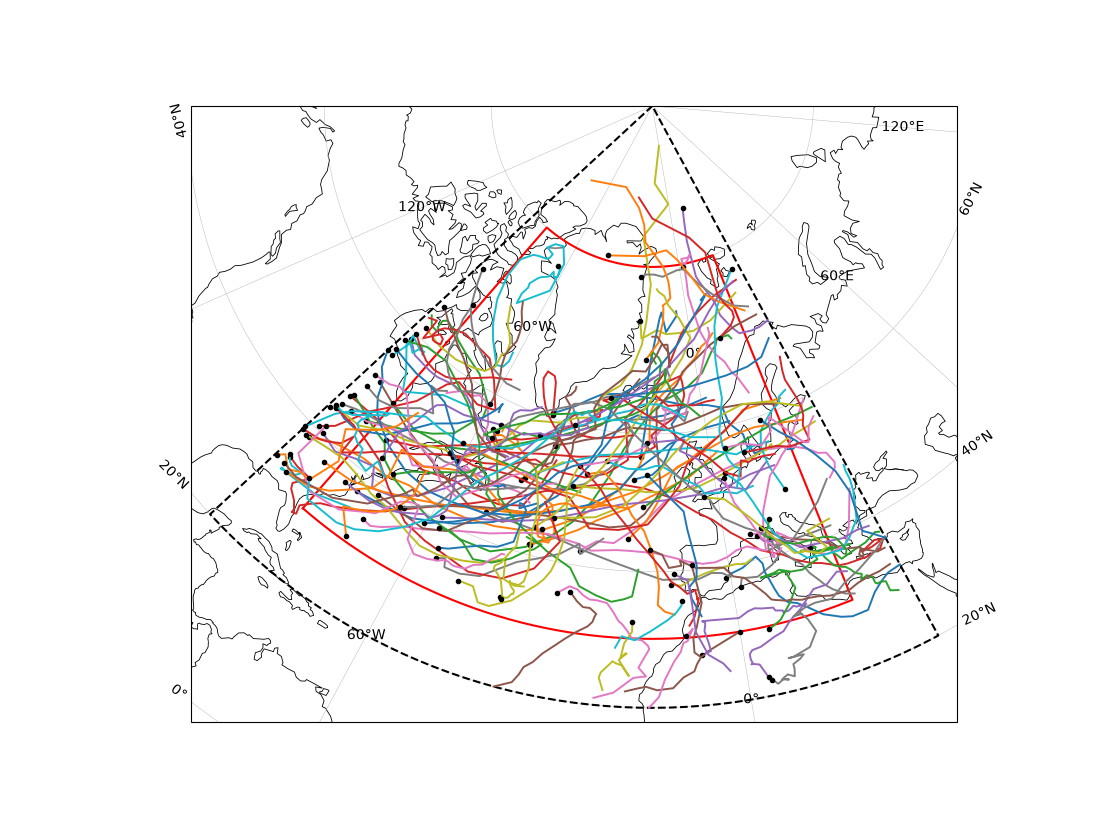

In [40]:
ax= val.plot_regional_tracks(tracks, region=REGION, domain=DOMAIN)

In [41]:
comparison, matches_df = val.compare_to_validation(tracks_validation, tracks, matching="global_assignment",
                                               max_mean_separation_deg=2.0, min_overlap_fraction=0.6,
                                               variable="vo")

In [42]:
matches_df

,reference_id,candidate_id,overlap_fraction,overlap_count,mean_sep_km,max_sep_km,ref_points,cand_points,ref_peak,cand_peak,n_eligible_candidates,intensity_bias,intensity_rmse
0,700,800,1.000000,23,9.852262,23.625711,23,23,0.000116,0.000116,1,-5.371071e-07,9.903014e-07
1,800,700,1.000000,28,13.054244,44.541765,28,28,0.000061,0.000063,1,-2.238876e-07,1.761763e-06
2,1100,1300,1.000000,20,17.658912,29.382206,20,20,0.000073,0.000074,1,9.786382e-07,1.137758e-06
3,5300,12000,0.965517,14,25.183438,70.593131,14,15,0.000032,0.000028,1,-3.835060e-06,3.896447e-06
4,7900,18400,0.933333,21,14.982633,113.863061,24,21,0.000120,0.000120,1,7.620640e-07,1.334991e-06
...,...,...,...,...,...,...,...,...,...,...,...,...,...
107,244700,583100,0.645161,10,12.671189,24.148197,21,10,0.000056,0.000057,1,1.707673e-06,1.816092e-06
108,246100,586000,1.000000,11,9.935359,22.570465,11,11,0.000108,0.000107,1,2.201575e-08,8.090595e-07
109,252000,614700,1.000000,9,8.701087,17.262752,9,9,0.000098,0.000100,1,1.303396e-06,1.458557e-06
110,252100,596300,0.947368,9,47.204694,119.119379,9,10,0.000026,0.000032,1,-2.095711e-06,2.700700e-06


In [43]:
# result table 
results_df = pd.Series({
    "Hits": comparison.tp,
    "Miss": comparison.fn,
    "Extra": comparison.fp,
    "F1": comparison.f1, #
    "Precision": comparison.precision,
    "Recall": comparison.recall,
})
results_df

Hits         112.000000
Miss           8.000000
Extra         17.000000
F1             0.899598
Precision      0.868217
Recall         0.933333
dtype: float64

In [44]:
comparison.precision?


Type:        property
String form: <property object at 0x3106b4950>
Docstring:   Candidate-side precision: matched / candidate_count.

Number of verified tracks: 112
Number of extra tracks: 17
Number of verified validation tracks: 112
Number of missed tracks: 8
22.25
22.689558


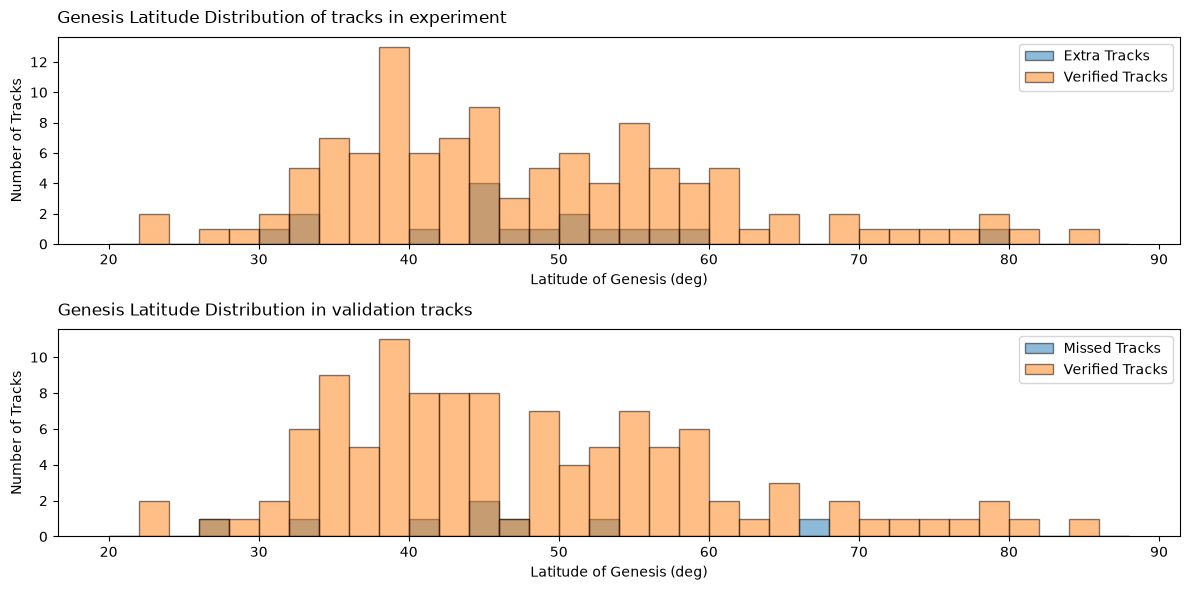

In [45]:
#creating list for verified
verified_tracks = matches_df['candidate_id']
verified_val = matches_df['reference_id']

#remember to filter the summary dataframes to only include the tracks that were kept
summary_val_filtered = summary_validation[summary_validation['keep'] == True]
summary_filtered = summary[summary['keep'] == True]


kept_tracks = summary_filtered[summary_filtered['track_id'].isin(verified_tracks)]
extra_tracks = summary_filtered[~summary_filtered['track_id'].isin(verified_tracks)]

kept_val_tracks = summary_val_filtered[summary_val_filtered['track_id'].isin(verified_val)]
missed_tracks = summary_val_filtered[~summary_val_filtered['track_id'].isin(verified_val)]




print(f"Number of verified tracks: {len(kept_tracks)}")
print(f"Number of extra tracks: {len(extra_tracks)}")
print(f"Number of verified validation tracks: {len(kept_val_tracks)}")
print(f"Number of missed tracks: {len(missed_tracks)}")

print(np.min(kept_tracks["lat_genesis"].values))
print(np.min(kept_val_tracks["lat_genesis"].values))

genesis_ver = kept_tracks["lat_genesis"].values
genesis_missed = missed_tracks["lat_genesis"].values
genesis_ex = extra_tracks["lat_genesis"].values
genesis_val = kept_val_tracks["lat_genesis"].values

counts, edges = np.histogram(genesis_ver, bins=np.arange(20, 90, 2), density=False)
counts_missed, edges_missed = np.histogram(genesis_missed, bins=np.arange(20, 90, 2), density=False)
counts_dis, edges_dis = np.histogram(genesis_ex, bins=np.arange(20, 90, 2), density=False)
counts_val, edges_val = np.histogram(genesis_val, bins=np.arange(20, 90, 2), density=False)

fig, ax = plt.subplots(2,1,figsize=(12, 6), sharex=False)
ax[0].bar(edges_dis[:-1], counts_dis, width=2, align="edge", edgecolor="black", label="Extra Tracks", alpha=0.5)
ax[0].bar(edges[:-1], counts, width=2, align="edge", edgecolor="black", label="Verified Tracks", alpha=0.5)

ax[1].bar(edges_missed[:-1], counts_missed, width=2, align="edge", edgecolor="black", label="Missed Tracks", alpha=0.5)
ax[1].bar(edges_val[:-1], counts_val, width=2, align="edge", edgecolor="black", label="Verified Tracks", alpha=0.5)


ax[0].set_xlabel("Latitude of Genesis (deg)")
ax[0].set_ylabel("Number of Tracks")
ax[0].set_title("Genesis Latitude Distribution of tracks in experiment", fontsize=12, pad=10, x=0.2)
ax[0].legend()

ax[1].set_xlabel("Latitude of Genesis (deg)")
ax[1].set_ylabel("Number of Tracks")
ax[1].set_title("Genesis Latitude Distribution in validation tracks", fontsize=12, pad=10, x=0.185)
ax[1].legend()

plt.tight_layout()

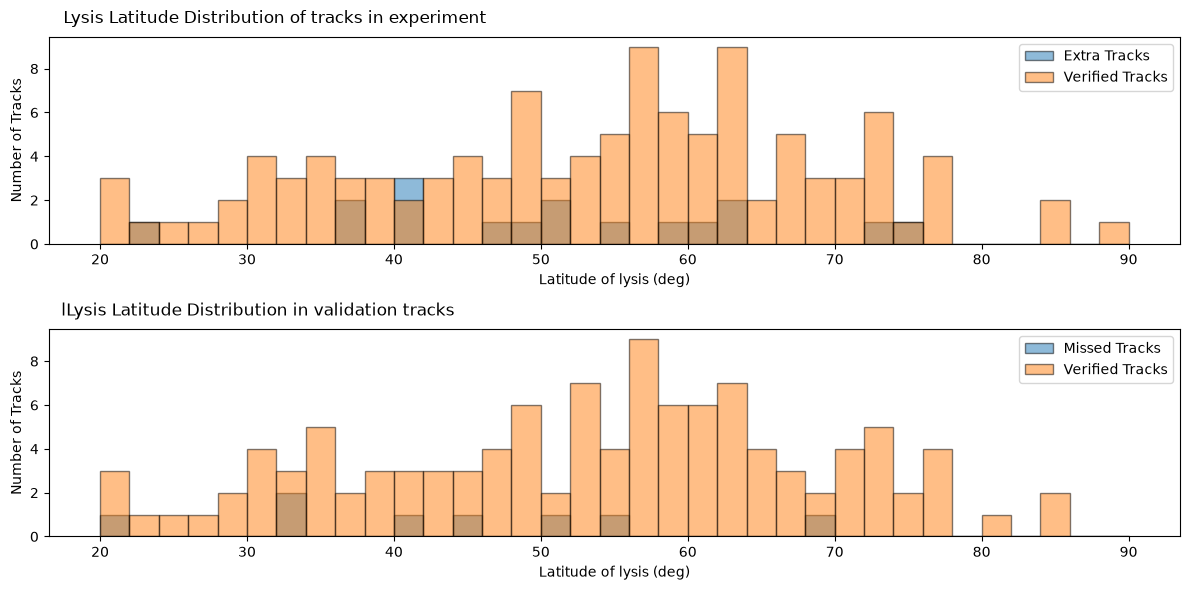

In [46]:
lysis_ver = kept_tracks["lat_lysis"].values
lysis_missed = missed_tracks["lat_lysis"].values
lysis_ex = extra_tracks["lat_lysis"].values
lysis_val = kept_val_tracks["lat_lysis"].values

counts, edges = np.histogram(lysis_ver, bins=np.arange(20, 92, 2), density=False)
counts_missed, edges_missed = np.histogram(lysis_missed, bins=np.arange(20, 92, 2), density=False)
counts_dis, edges_dis = np.histogram(lysis_ex, bins=np.arange(20, 92, 2), density=False)
counts_val, edges_val = np.histogram(lysis_val, bins=np.arange(20, 92, 2), density=False)

fig, ax = plt.subplots(2,1,figsize=(12, 6), sharex=False)
ax[0].bar(edges_dis[:-1], counts_dis, width=2, align="edge", edgecolor="black", label="Extra Tracks", alpha=0.5)
ax[0].bar(edges[:-1], counts, width=2, align="edge", edgecolor="black", label="Verified Tracks", alpha=0.5)

ax[1].bar(edges_missed[:-1], counts_missed, width=2, align="edge", edgecolor="black", label="Missed Tracks", alpha=0.5)
ax[1].bar(edges_val[:-1], counts_val, width=2, align="edge", edgecolor="black", label="Verified Tracks", alpha=0.5)


ax[0].set_xlabel("Latitude of lysis (deg)")
ax[0].set_ylabel("Number of Tracks")
ax[0].set_title("Lysis Latitude Distribution of tracks in experiment", fontsize=12, pad=10, x=0.2)
ax[0].legend()

ax[1].set_xlabel("Latitude of lysis (deg)")
ax[1].set_ylabel("Number of Tracks")
ax[1].set_title("lLysis Latitude Distribution in validation tracks", fontsize=12, pad=10, x=0.185)
ax[1].legend()

plt.tight_layout()

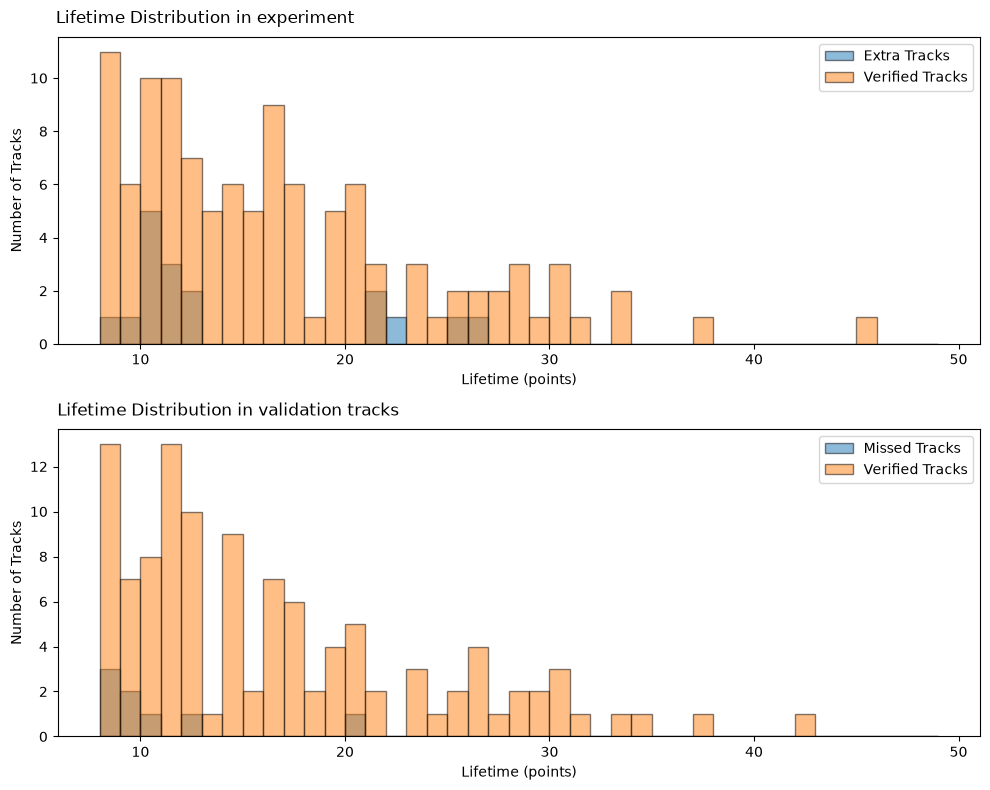

In [47]:
lifetime = kept_tracks["n_points"].values
lifetime_missed = missed_tracks["n_points"].values
lifetime_ex = extra_tracks["n_points"].values
lifetime_val = kept_val_tracks["n_points"].values

counts, edges = np.histogram(lifetime, bins=np.arange(8, 50, 1))
counts_missed, edges_missed = np.histogram(lifetime_missed, bins=np.arange(8, 50, 1))
counts_dis, edges_dis = np.histogram(lifetime_ex, bins=np.arange(8, 50, 1))
counts_val, edges_val = np.histogram(lifetime_val, bins=np.arange(8, 50, 1))

fig, ax = plt.subplots(2,1,figsize=(10, 8))
ax[0].bar(edges_dis[:-1], counts_dis, width=1, align="edge", edgecolor="black", label="Extra Tracks", alpha=0.5)
ax[0].bar(edges[:-1], counts, width=1, align="edge", edgecolor="black", label="Verified Tracks", alpha=0.5)

ax[1].bar(edges_missed[:-1], counts_missed, width=1, align="edge", edgecolor="black", label="Missed Tracks", alpha=0.5)
ax[1].bar(edges_val[:-1], counts_val, width=1, align="edge", edgecolor="black", label="Verified Tracks", alpha=0.5)

ax[0].set_xlabel("Lifetime (points)")
ax[0].set_ylabel("Number of Tracks")
ax[0].set_title("Lifetime Distribution in experiment", fontsize=12, pad=10, x=0.16)
ax[0].legend()

ax[1].set_xlabel("Lifetime (points)")
ax[1].set_ylabel("Number of Tracks")
ax[1].set_title("Lifetime Distribution in validation tracks", fontsize=12, pad=10, x=0.185)
ax[1].legend()

plt.tight_layout()

6.141991616459565
4.379232000000001
4.3236046622041595
5.872454


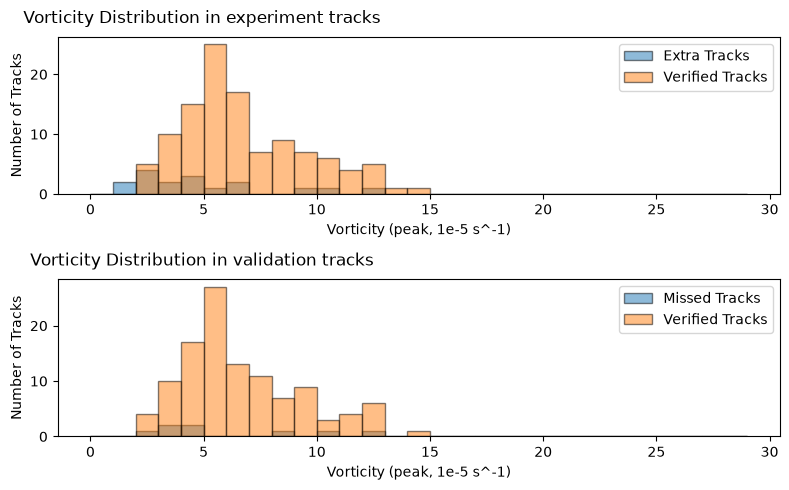

In [48]:
vo_peak = kept_tracks["vo_peak"].values*1e5
vo_peak_missed = missed_tracks["vo_peak"].values*1e5
vo_peak_ex = extra_tracks["vo_peak"].values*1e5
vo_peak_val = kept_val_tracks["vo_peak"].values*1e5

counts, edges = np.histogram(vo_peak, bins=np.arange(0, 30, 1))
counts_missed, edges_missed = np.histogram(vo_peak_missed, bins=np.arange(0, 30, 1))
counts_dis, edges_dis = np.histogram(vo_peak_ex, bins=np.arange(0, 30, 1))
counts_val, edges_val = np.histogram(vo_peak_val, bins=np.arange(0, 30, 1))
fig, ax = plt.subplots(2,1, figsize=(8, 5))
ax[0].bar(edges_dis[:-1], counts_dis, width=1, align="edge", edgecolor="black", label="Extra Tracks", alpha=0.5)
ax[0].bar(edges[:-1], counts, width=1, align="edge", edgecolor="black", label="Verified Tracks", alpha=0.5)

ax[1].bar(edges_missed[:-1], counts_missed, width=1, align="edge", edgecolor="black", label="Missed Tracks", alpha=0.5)
ax[1].bar(edges_val[:-1], counts_val, width=1, align="edge", edgecolor="black", label="Verified Tracks", alpha=0.5)


ax[0].set_xlabel("Vorticity (peak, 1e-5 s^-1)")
ax[0].set_ylabel("Number of Tracks")
ax[0].set_title("Vorticity Distribution in experiment tracks", fontsize=12, pad=10, x=0.2)
ax[0].legend()

ax[1].set_xlabel("Vorticity (peak, 1e-5 s^-1)")
ax[1].set_ylabel("Number of Tracks")
ax[1].set_title("Vorticity Distribution in validation tracks", fontsize=12, pad=10, x=0.2)
ax[1].legend()

plt.tight_layout()

print(np.median(kept_tracks["vo_peak"].values*1e5))
print(np.median(missed_tracks["vo_peak"].values*1e5))
print(np.median(extra_tracks["vo_peak"].values*1e5))
print(np.median(kept_val_tracks["vo_peak"].values*1e5))

/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


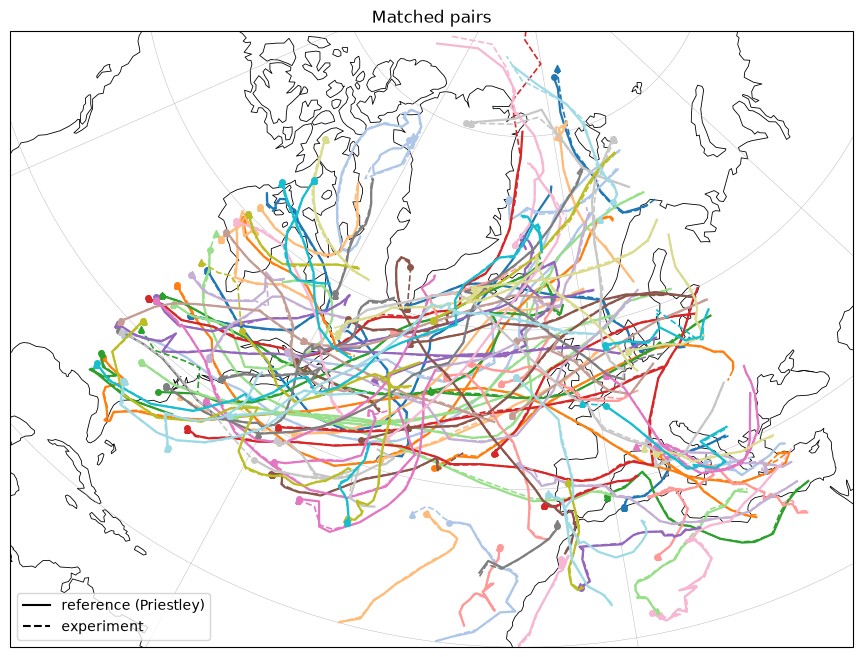

In [49]:
pc = ccrs.PlateCarree()
proj = ccrs.LambertConformal(central_longitude=-15, central_latitude=55)

# look up tracks by id
ref_by_id = {tr.track_id: tr for tr in tracks_validation}
cand_by_id = {tr.track_id: tr for tr in tracks}

fig, ax = plt.subplots(figsize=(12, 8), subplot_kw={"projection": proj})
ax.coastlines(linewidth=0.6)
ax.gridlines(linewidth=0.3)
ax.set_extent([DOMAIN[0], DOMAIN[1], DOMAIN[2], 85], crs=pc)

colors = plt.cm.tab20(np.linspace(0, 1, len(matches_df)))
for row, c in zip(matches_df.itertuples(), colors):
    ref = ref_by_id[int(row.reference_id)]
    cand = cand_by_id[int(row.candidate_id)]
    ax.plot(ref.lons, ref.lats, "-", color=c, lw=1.6, transform=pc)
    ax.plot(cand.lons, cand.lats, "--", color=c, lw=1.2, transform=pc)
    ax.plot(ref.lons[0], ref.lats[0], "o", color=c, ms=4, transform=pc)    # reference start
    ax.plot(cand.lons[0], cand.lats[0], "^", color=c, ms=4, transform=pc)  # experiment start

ax.plot([], [], "k-", label="reference (Priestley)")
ax.plot([], [], "k--", label="experiment")
ax.legend(loc="lower left")
ax.set_title(f"Matched pairs")
plt.show()

Number of extra tracks: 17
Number of extra tracks plotted: 17


/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


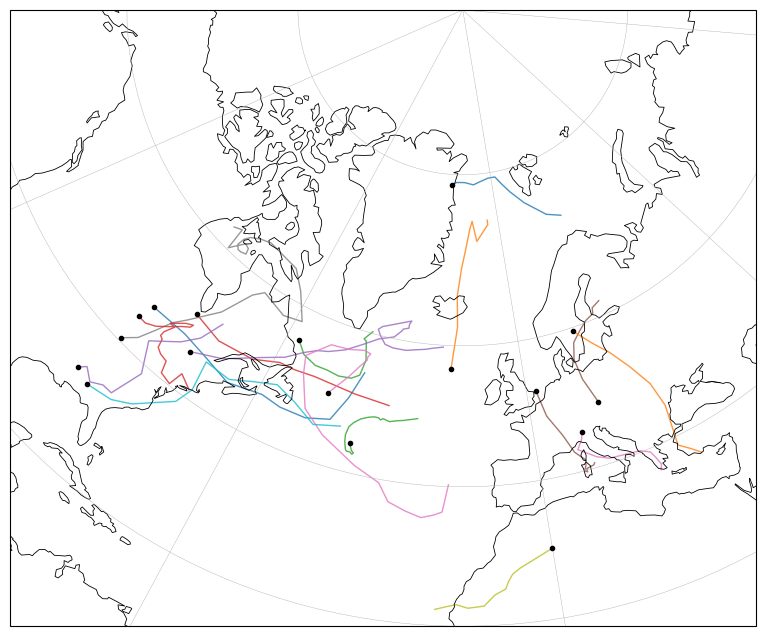

In [50]:
pc = ccrs.PlateCarree()
proj = ccrs.LambertConformal(central_longitude=-15, central_latitude=55)

fig, ax = plt.subplots(figsize=(12, 8), subplot_kw={"projection": proj})
ax.coastlines(linewidth=0.6)
ax.gridlines(linewidth=0.3)
ax.set_extent([DOMAIN[0], DOMAIN[1], DOMAIN[2], 90], crs=pc)
i =0
print(f"Number of extra tracks: {len(extra_tracks)}")
for tr in tracks:
    if tr.track_id in extra_tracks['track_id'].values:
        ax.plot(tr.lons, tr.lats, "-", alpha=0.8, lw=1, transform=pc, zorder=0)
        ax.plot(tr.lons[0], tr.lats[0], "k.", ms=6, transform=pc)
        i+=1
print(f"Number of extra tracks plotted: {i}")